# Phase 3 — Analyse exploratoire des rendements

L’analyse porte sur les observations disponibles jusqu’au 31 décembre 2022. Les phases précédentes ont déjà présenté l’historique complet, ce qui limite le caractère inédit des périodes d’évaluation ultérieures.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
summary = pd.read_csv(ROOT / 'reports/phase3_summary.csv')
summary

,index,valid_returns,mean_daily_return,daily_std,skewness,excess_kurtosis,minimum,maximum
0,S&P 500,1591,0.000354,0.012505,-0.867048,15.931691,-0.127652,0.089683
1,CAC 40,1619,0.000221,0.011983,-0.997227,15.251858,-0.130983,0.080561
2,FTSE 100,1594,0.000047,0.010396,-1.123069,16.519942,-0.115117,0.086664


## 1. Statistiques descriptives

La moyenne décrit le rendement logarithmique quotidien moyen ; l’écart-type mesure sa dispersion. Une asymétrie négative traduit une influence plus forte de la queue négative. L’excès de kurtosis caractérise la distribution par rapport à la référence normale, dont l’excès théorique est nul.

In [2]:
table = summary[['index', 'daily_std', 'minimum', 'maximum']].copy()
for col in table.columns[1:]: table[col] = table[col].map(lambda x: f'{x:.2%}')
table

,index,daily_std,minimum,maximum
0,S&P 500,1.25%,-12.77%,8.97%
1,CAC 40,1.20%,-13.10%,8.06%
2,FTSE 100,1.04%,-11.51%,8.67%


## 2. Distribution des rendements

Les histogrammes représentent la concentration des rendements autour de zéro et les variations extrêmes de l’échantillon.

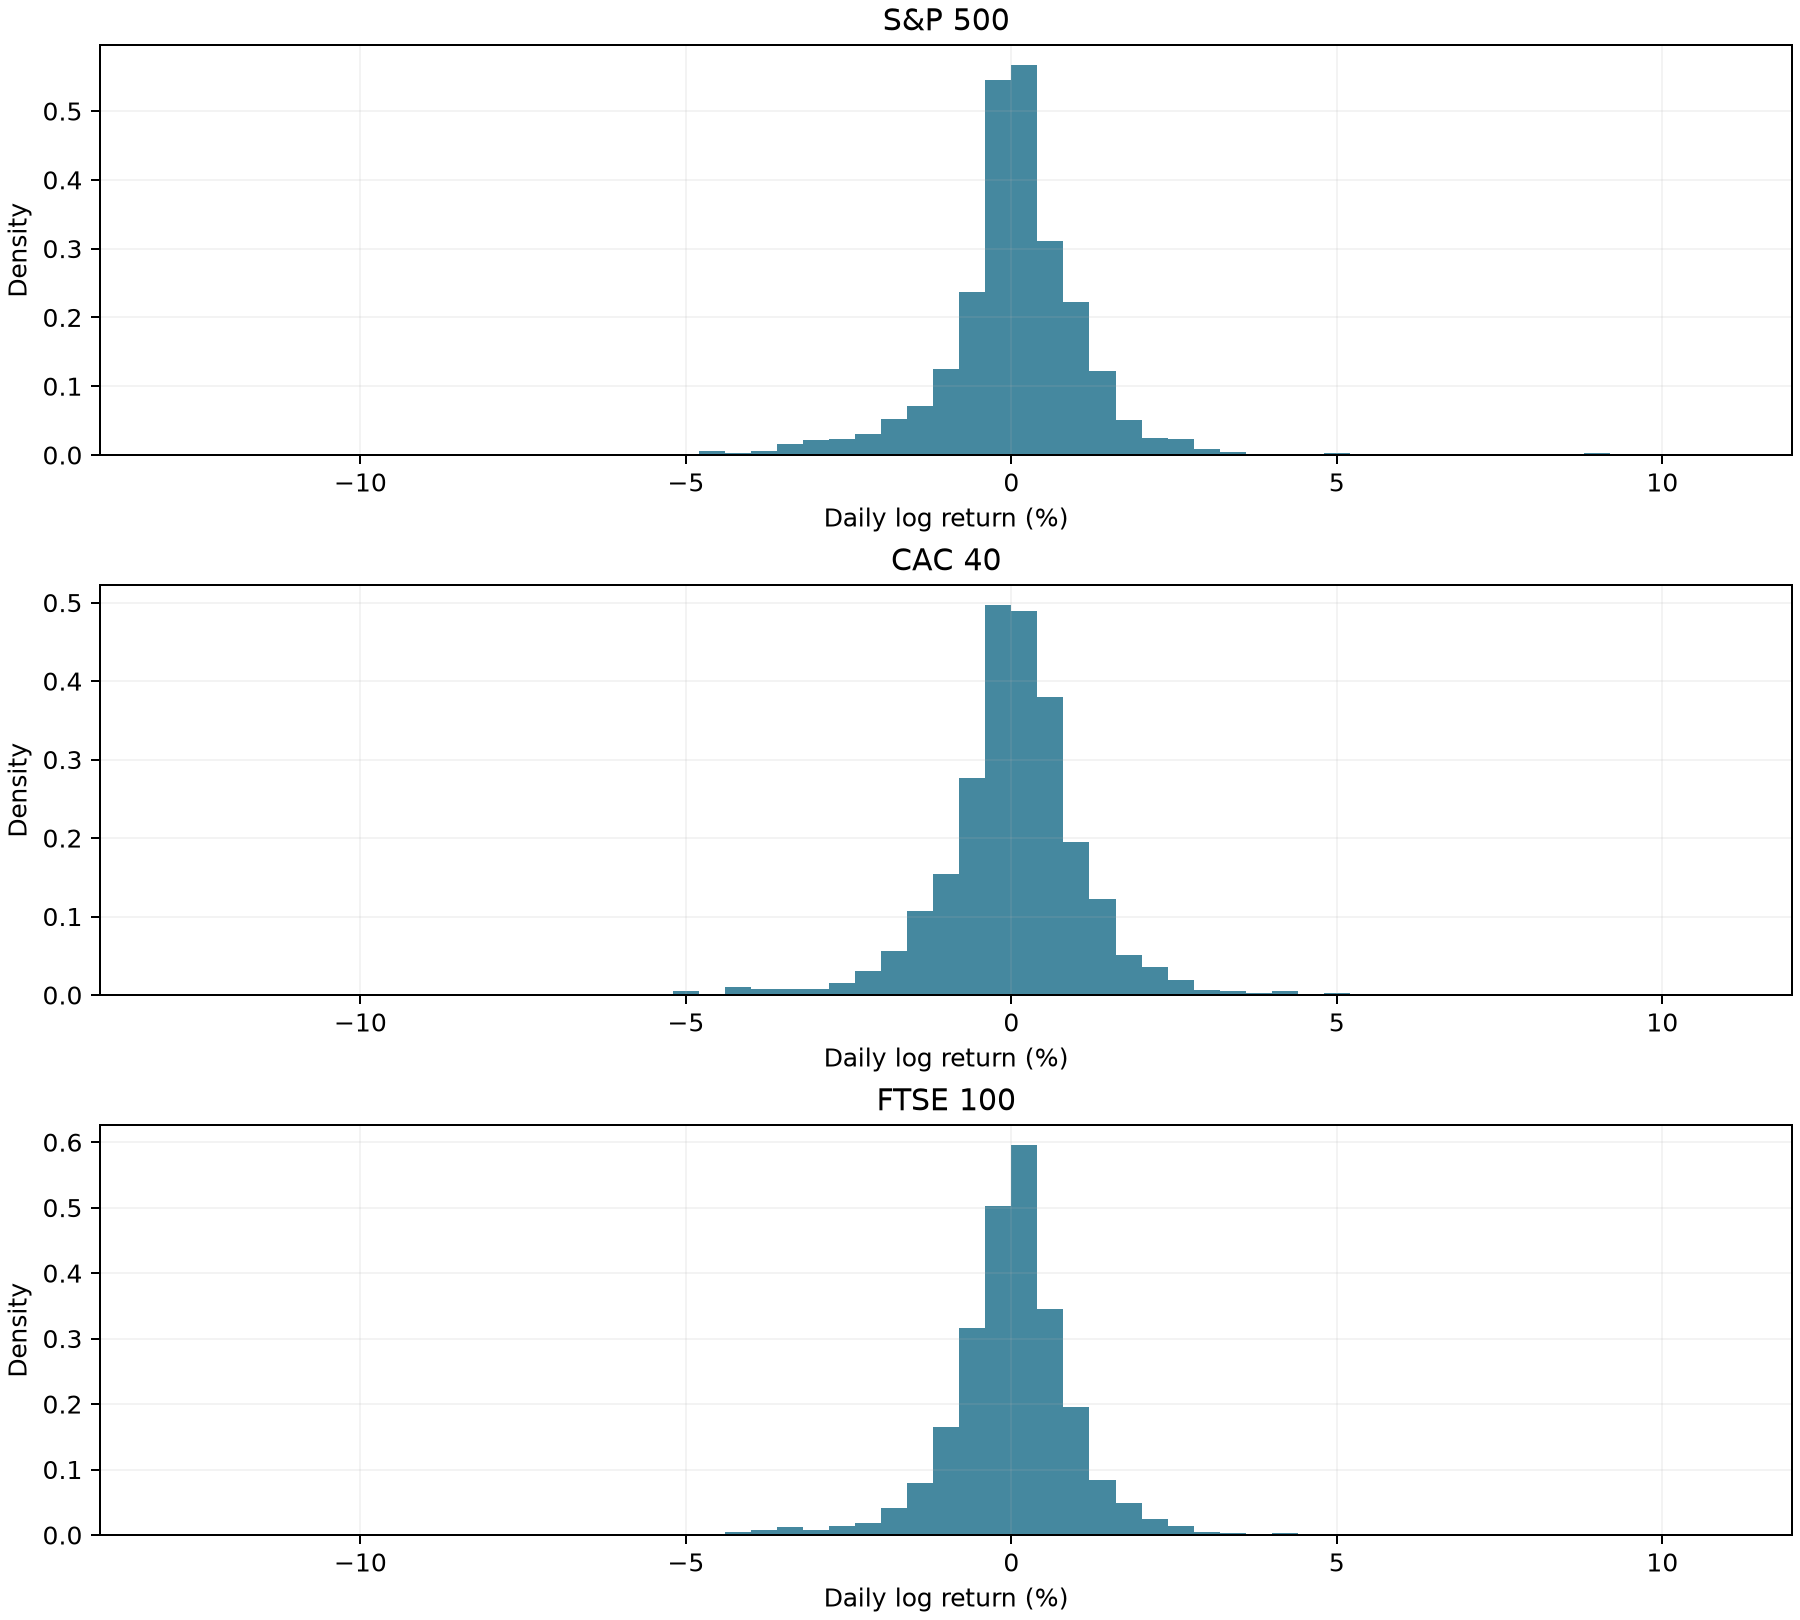

In [3]:
display(Image(filename=str(ROOT / 'reports/figures/phase3_distributions.png')))

## 3. Volatilité mensuelle et mois extrêmes

Les mois de volatilité minimale et maximale sont identifiés rétrospectivement sur la période d’exploration. Le mois initial partiel et les mois contenant des rendements manquants sont exclus.

In [4]:
pd.read_csv(ROOT / 'reports/phase3_period_examples.csv')

,index,classification,month,valid_returns,annualized_volatility
0,S&P 500,calm,2017-02,19,0.046215
1,S&P 500,turbulent,2020-03,22,0.941870
2,CAC 40,calm,2019-11,21,0.059565
3,CAC 40,turbulent,2020-03,22,0.770676
4,FTSE 100,calm,2017-02,20,0.053031
5,FTSE 100,turbulent,2020-03,22,0.698316


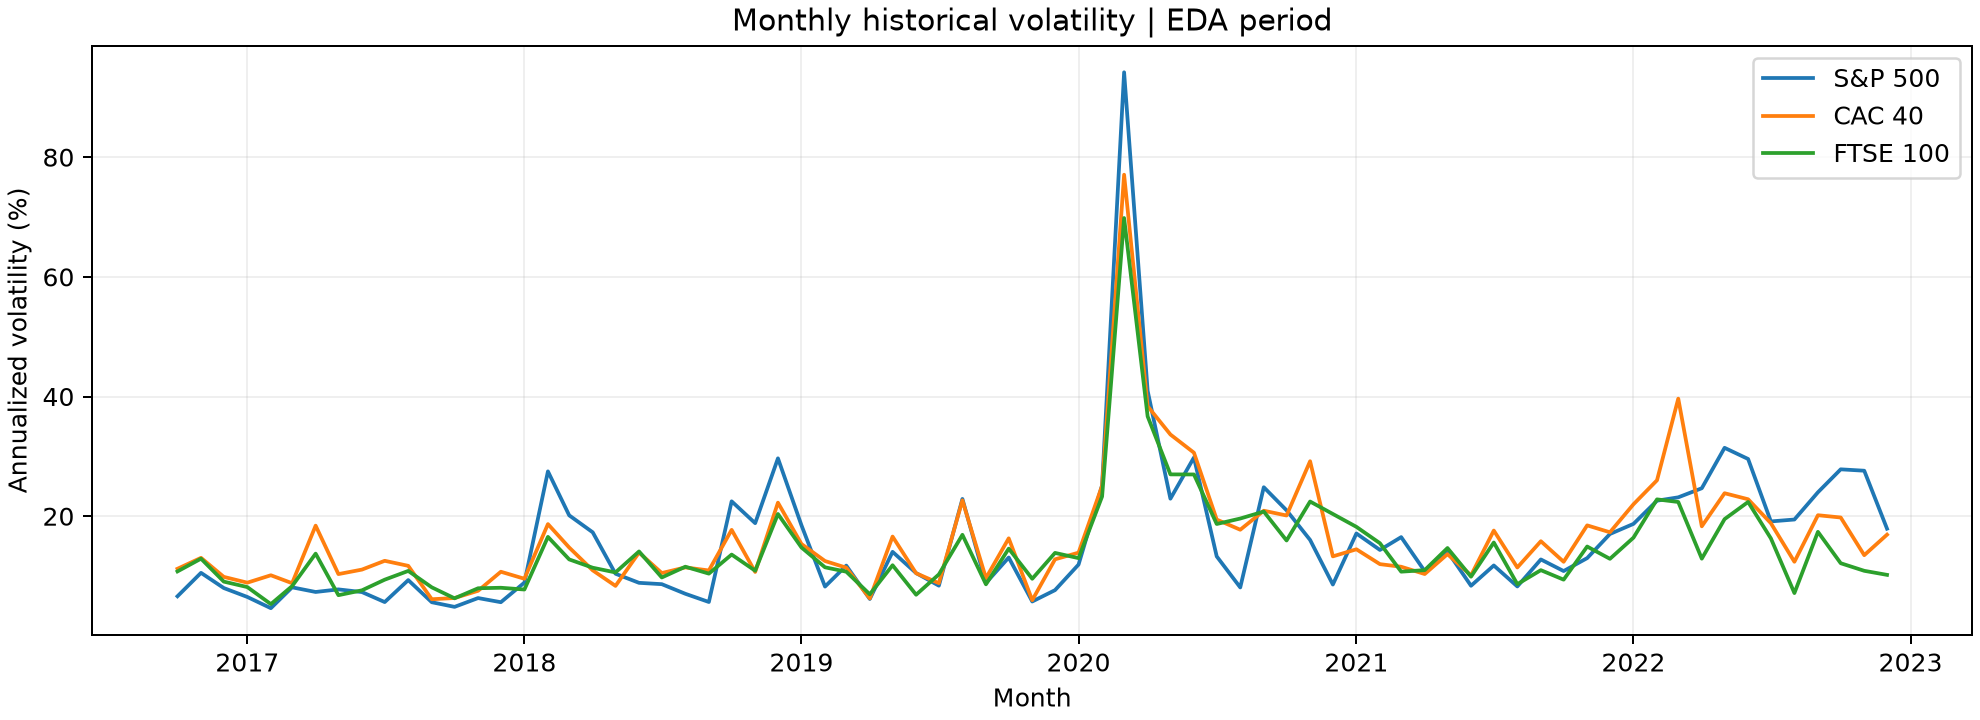

In [5]:
display(Image(filename=str(ROOT / 'reports/figures/phase3_monthly_volatility.png')))

## 4. Autocorrélation des rendements

L’autocorrélation mesure l’association linéaire à un retard donné. Les rendements au carré décrivent l’amplitude sans conserver le signe. Leur autocorrélation positive est compatible avec un regroupement des fortes variations. Une faible autocorrélation des rendements ne suffit pas à établir leur indépendance.

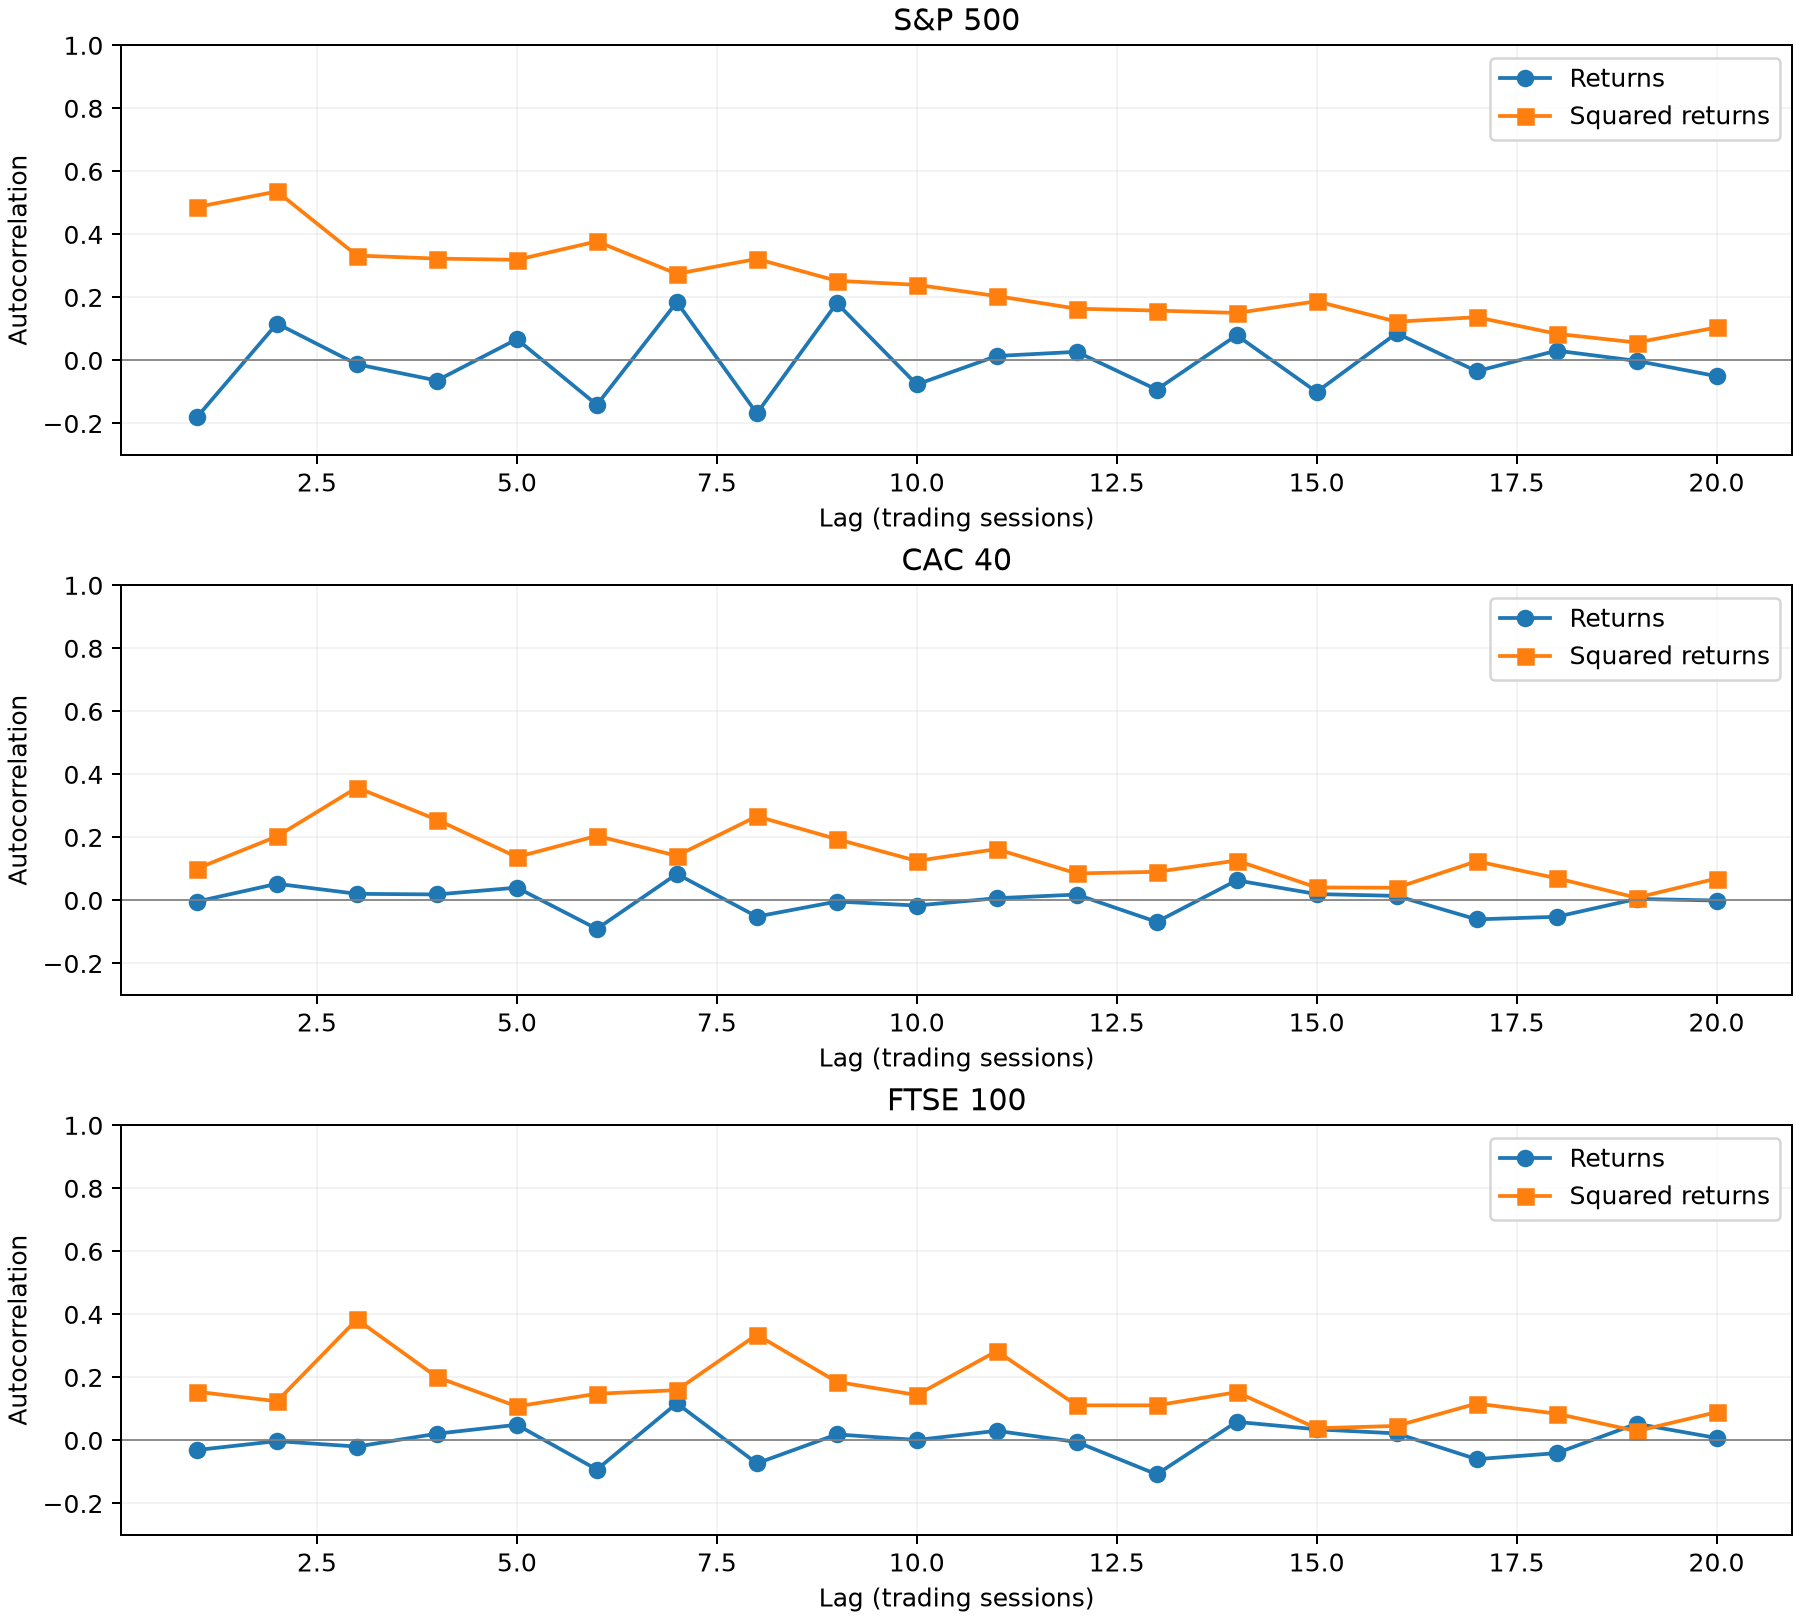

In [6]:
display(Image(filename=str(ROOT / 'reports/figures/phase3_autocorrelation.png')))

## 5. Corrélations entre marchés

La comparaison utilise les dates communes valides. Les différences d’horaires de clôture et de jours fériés limitent la synchronisation des intervalles de rendement.

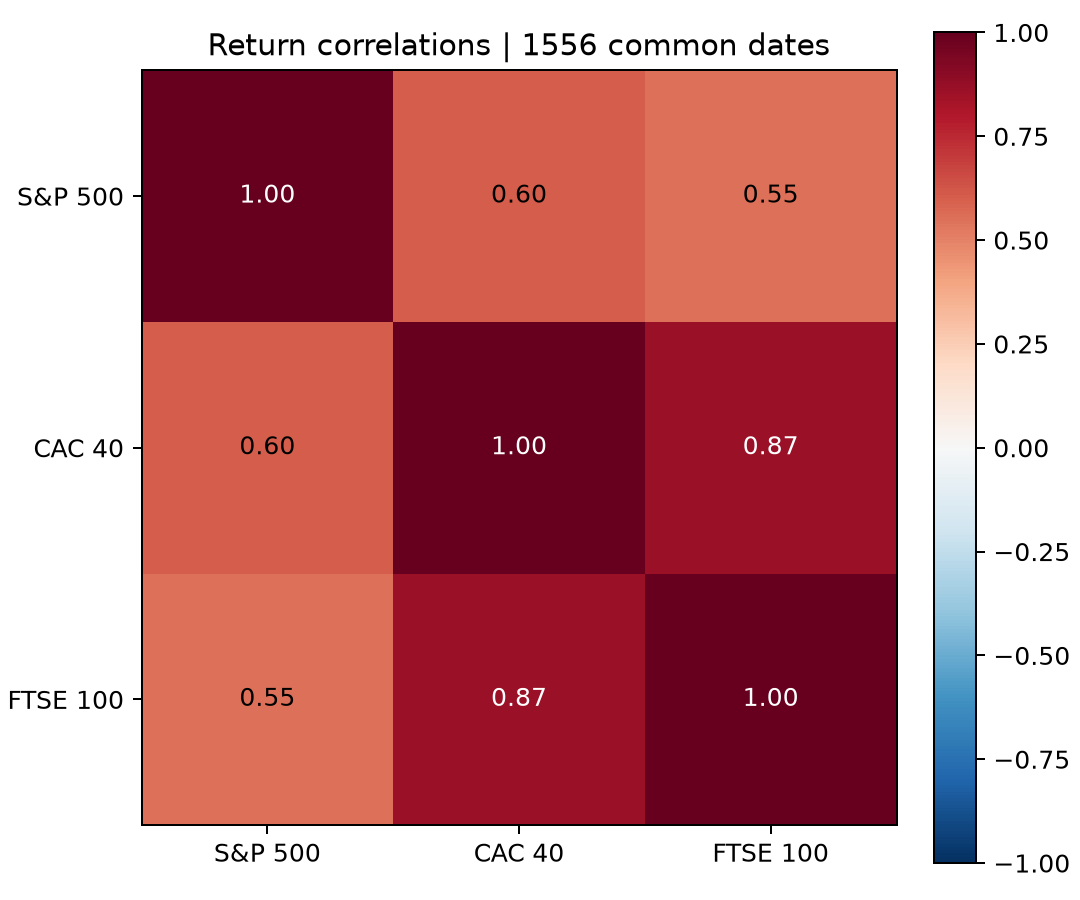

,S&P 500,CAC 40,FTSE 100
S&P 500,1.000000,0.602745,0.553616
CAC 40,0.602745,1.000000,0.866582
FTSE 100,0.553616,0.866582,1.000000


In [7]:
display(Image(filename=str(ROOT / 'reports/figures/phase3_correlations.png')))
pd.read_csv(ROOT / 'reports/phase3_common_date_correlations.csv', index_col=0)

## 6. Protocole de prévision

- Exploration et initialisation : du 6 septembre 2016 au 31 décembre 2022.
- Validation : du 1er janvier 2023 au 31 décembre 2024.
- Test : du 1er janvier 2025 au 4 septembre 2026.
- Cible : variance de la séance suivante, approchée par le rendement au carré sous une hypothèse de moyenne conditionnelle proche de zéro.
- Méthodes : fenêtre mobile et EWMA, avec paramètres fixes.
- Les entrées ou cibles affectées par une lacune sont traitées selon les règles d’éligibilité.

L’examen préalable de l’historique complet est pris en compte dans les limites du protocole.